# Used Cars Cost Prediction

**Acmegrade internship project - beginner walkthrough**

This notebook uses the real public CarDekho dataset to estimate `Selling_Price`. It covers loading and inspecting the CSV, cleaning duplicate or invalid target rows, exploratory charts, model training, held-out evaluation, and conclusions. The dataset source and download instructions are documented in `data/README.md`. No invented rows or metrics are used.

**Dataset:** `data/car data.csv`; target column: `Selling_Price`.


## 1. Import the tools

Pandas works with tables, Matplotlib and Seaborn make charts, and scikit-learn provides the train/test split, preprocessing, model, and evaluation measures. Run this notebook using the project virtual environment described in the project README.

In [1]:
from pathlib import Path
import sys

try:
    import joblib
    import matplotlib.pyplot as plt
    import pandas as pd
    import seaborn as sns
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
except ImportError as exc:
    raise ImportError(
        f"Missing package: {exc.name}. Select the project .venv interpreter and "
        "install packages with `python -m pip install -r requirements.txt`."
    ) from exc

working_directory = Path.cwd().resolve()
project_candidates = [working_directory, *working_directory.parents]
project_candidates.append(working_directory / "used-car-price-prediction")
PROJECT_DIR = next(
    (
        candidate
        for candidate in project_candidates
        if (candidate / "train_model.py").is_file()
        and (candidate / "data").is_dir()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not locate the used-car-price-prediction project. Open its folder "
        "or the Desktop as the VS Code workspace, then rerun this cell."
    )

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from train_model import (
    DATA_DIR,
    OUTPUT_DIR,
    TARGET,
    build_model,
    load_dataset,
    prepare_dataset,
    split_dataset,
)

sns.set_theme(style="whitegrid")
print(f"Project folder: {PROJECT_DIR}")
print(f"Dataset folder: {DATA_DIR}")

Project folder: C:\Users\dhakd\OneDrive\Desktop\used-car-price-prediction
Dataset folder: C:\Users\dhakd\OneDrive\Desktop\used-car-price-prediction\data


## 2. Load the real dataset

The notebook looks for CSV files in `data/` and selects one containing the expected `Selling_Price` target. If it cannot find one, download the dataset using the instructions in `data/README.md`; do not replace the missing dataset with made-up rows.

In [2]:
cars = load_dataset(DATA_DIR)
print(f"Rows and columns: {cars.shape}")
display(cars.head())

Using dataset: C:\Users\dhakd\OneDrive\Desktop\used-car-price-prediction\data\car data.csv
Rows and columns: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 3. Inspect and clean the data

First inspect column types and missing values. Duplicate rows are removed, and rows without a usable selling price cannot be used as training examples. Feature values are kept in their original columns; the model pipeline will fill missing feature values appropriately without learning from the test set.

In [3]:
print("Column types and non-null counts:")
display(cars.info())
print("Missing values by column:")
display(cars.isna().sum().sort_values(ascending=False))
print(f"Duplicate rows before cleaning: {cars.duplicated().sum()}")

clean_cars = prepare_dataset(cars)
print(f"Rows after removing duplicates and invalid target values: {len(clean_cars)}")
display(clean_cars.describe(include="all").transpose())

Column types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


None

Missing values by column:


Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate rows before cleaning: 2
Rows after removing duplicates and invalid target values: 299


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,299,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,299.0,NaN,NaN,NaN,2013.615385,2.896868,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,299.0,NaN,NaN,NaN,4.589632,4.98424,0.1,0.85,3.51,6.0,35.0
Present_Price,299.0,NaN,NaN,NaN,7.541037,8.567887,0.32,1.2,6.1,9.84,92.6
Kms_Driven,299.0,NaN,NaN,NaN,36916.752508,39015.170352,500.0,15000.0,32000.0,48883.5,500000.0
Fuel_Type,299,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Seller_Type,299,2,Dealer,193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,299,2,Manual,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,299.0,NaN,NaN,NaN,0.043478,0.24872,0.0,0.0,0.0,0.0,3.0


## 4. Explore the data with charts

These plots help us understand the target-price distribution and how it varies with vehicle age and kilometres driven. The plots describe this dataset; they do not prove that any feature causes a price change.

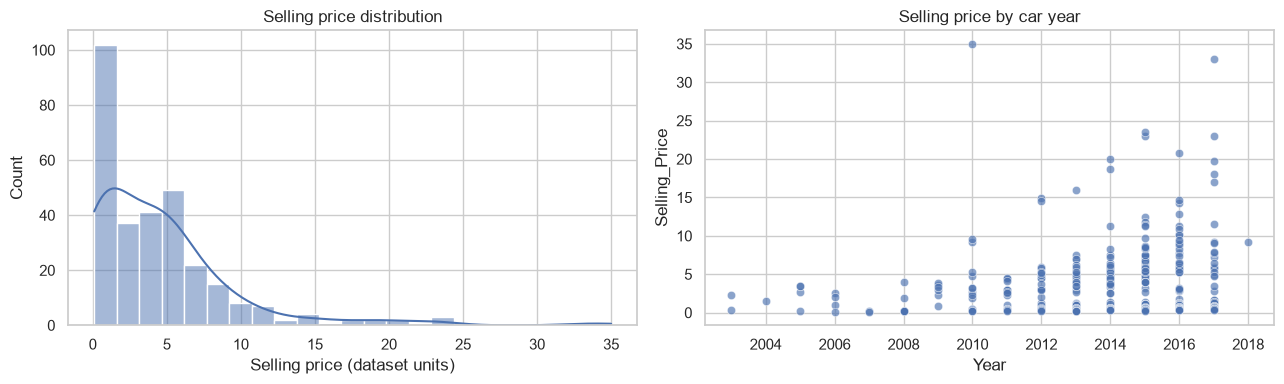

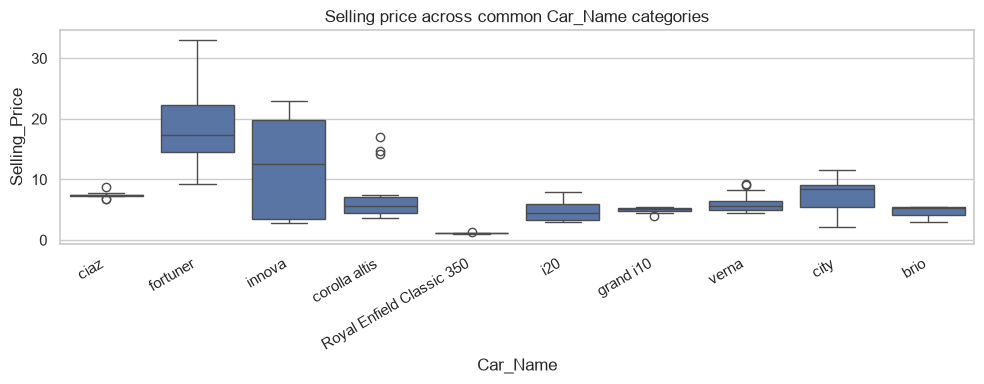

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=clean_cars, x=TARGET, kde=True, ax=axes[0])
axes[0].set_title("Selling price distribution")
axes[0].set_xlabel("Selling price (dataset units)")

if "Year" in clean_cars.columns:
    sns.scatterplot(data=clean_cars, x="Year", y=TARGET, alpha=0.65, ax=axes[1])
    axes[1].set_title("Selling price by car year")
elif "Kms_Driven" in clean_cars.columns:
    sns.scatterplot(data=clean_cars, x="Kms_Driven", y=TARGET, alpha=0.65, ax=axes[1])
    axes[1].set_title("Selling price by kilometres driven")
else:
    axes[1].text(0.5, 0.5, "No Year or Kms_Driven column", ha="center", va="center")
    axes[1].set_axis_off()
plt.tight_layout()
plt.show()

categorical_columns = clean_cars.select_dtypes(exclude="number").columns.tolist()
if categorical_columns:
    chart_column = categorical_columns[0]
    top_values = clean_cars[chart_column].value_counts().head(10).index
    chart_data = clean_cars[clean_cars[chart_column].isin(top_values)]
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=chart_data, x=chart_column, y=TARGET)
    plt.title(f"Selling price across common {chart_column} categories")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns are available for a category chart.")

## 5. Prepare features and train a model

We predict `Selling_Price` from the other columns. Numeric features get median-value imputation; text categories get most-common-value imputation and one-hot encoding. A Random Forest regressor is trained on 80% of the data. The remaining 20% is held out for evaluation. The fixed random seed makes the split repeatable.

In [5]:
X_train, X_test, y_train, y_test = split_dataset(clean_cars)
model = build_model(X_train)
model.fit(X_train, y_train)
print(f"Training rows: {len(X_train)}; test rows: {len(X_test)}")

Training rows: 239; test rows: 60


## 6. Evaluate on held-out data

- **MAE** is the average absolute prediction error, in the same price units as `Selling_Price`; lower is better.
- **RMSE** is also in price units and penalizes larger errors more heavily; lower is better.
- **R-squared** compares the model with a simple mean-price baseline; closer to 1 is generally better, but it can be negative when the model performs poorly.

These are results only for this real dataset and this held-out split. They are not a guarantee of future performance.

Mean absolute error (MAE): 1.365
Root mean squared error (RMSE): 3.310
R-squared (R2): 0.575


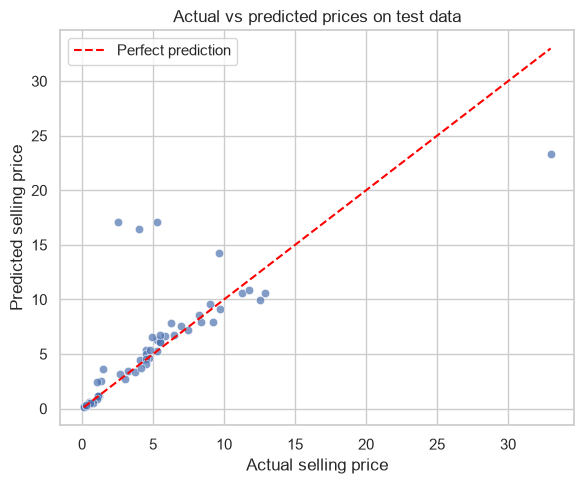

In [6]:
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)
print(f"Mean absolute error (MAE): {mae:.3f}")
print(f"Root mean squared error (RMSE): {rmse:.3f}")
print(f"R-squared (R2): {r2:.3f}")

plt.figure(figsize=(6, 5))
sns.scatterplot(x=y_test, y=predictions, alpha=0.7)
low = min(float(y_test.min()), float(predictions.min()))
high = max(float(y_test.max()), float(predictions.max()))
plt.plot([low, high], [low, high], linestyle="--", color="red", label="Perfect prediction")
plt.xlabel("Actual selling price")
plt.ylabel("Predicted selling price")
plt.title("Actual vs predicted prices on test data")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Save the fitted model

After training and evaluation succeed, save the complete preprocessing-and-model pipeline. Keeping preprocessing inside the pipeline ensures new input receives the same transformations. Only load joblib model files from sources you trust.

In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model_path = OUTPUT_DIR / "used_car_price_model.joblib"
joblib.dump(model, model_path)
print(f"Saved model: {model_path}")

Saved model: C:\Users\dhakd\OneDrive\Desktop\used-car-price-prediction\submission\used_car_price_model.joblib


## 8. Conclusions and next steps

This project demonstrates a full supervised-learning workflow: inspect and clean real data, explore it visually, preprocess numeric and categorical features, fit a regression model, and measure errors on held-out examples. Review the printed MAE and RMSE in the dataset's price units and the R-squared value before drawing conclusions. Improve the project by comparing additional models, checking unusual values, and validating performance with cross-validation. Do not claim a result unless this notebook has completed successfully with the real CarDekho dataset.

To create the shareable HTML report after all cells finish successfully, run this from the project folder:

```powershell
jupyter nbconvert --to html --execute notebooks/used_car_price_prediction.ipynb --output used_car_price_prediction.html --output-dir submission
```